#Steps to follow:(MLDLC)
0. Preprocess + EDA + Feature Selection
1. Extract input and output cols
2. Scale the values
3. Train test split
4. Train the model
5. Evaluate the model/model selection
6. Deploy the model

In [15]:
#import libraries
import numpy as np
import pandas as pd

In [16]:
#upload the dataset
from google.colab import files

uploaded = files.upload()

Saving Iris.csv to Iris (1).csv


In [17]:
#read the dataset
df = pd.read_csv('Iris.csv')

In [18]:
#get summary of uploaded dataset
df.head()

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,Iris-setosa
1,2,4.9,3.0,1.4,0.2,Iris-setosa
2,3,4.7,3.2,1.3,0.2,Iris-setosa
3,4,4.6,3.1,1.5,0.2,Iris-setosa
4,5,5.0,3.6,1.4,0.2,Iris-setosa


In [19]:
#remove the not required columns
df.iloc[:,1:]

,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,5.1,3.5,1.4,0.2,Iris-setosa
1,4.9,3.0,1.4,0.2,Iris-setosa
2,4.7,3.2,1.3,0.2,Iris-setosa
3,4.6,3.1,1.5,0.2,Iris-setosa
4,5.0,3.6,1.4,0.2,Iris-setosa
...,...,...,...,...,...
145,6.7,3.0,5.2,2.3,Iris-virginica
146,6.3,2.5,5.0,1.9,Iris-virginica
147,6.5,3.0,5.2,2.0,Iris-virginica
148,6.2,3.4,5.4,2.3,Iris-virginica


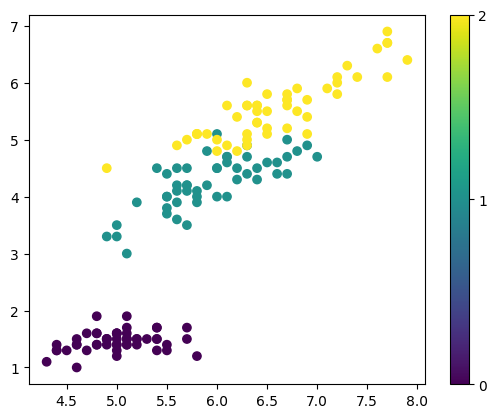

In [20]:
#EDA(understand the data)
import matplotlib.pyplot as plt
plt.scatter(df['SepalLengthCm'],df['PetalLengthCm'],c=df['Species'].astype('category').cat.codes, cmap='viridis')
plt.colorbar(ticks=[0,1,2])
plt.show()

In [21]:
#take the independent variables from the data
X = df.iloc[:,0:5]

In [22]:
X

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm
0,1,5.1,3.5,1.4,0.2
1,2,4.9,3.0,1.4,0.2
2,3,4.7,3.2,1.3,0.2
3,4,4.6,3.1,1.5,0.2
4,5,5.0,3.6,1.4,0.2
...,...,...,...,...,...
145,146,6.7,3.0,5.2,2.3
146,147,6.3,2.5,5.0,1.9
147,148,6.5,3.0,5.2,2.0
148,149,6.2,3.4,5.4,2.3


In [24]:
#take dependent variables from the data
Y = df.iloc[:,-1]

In [25]:
Y

,Species
0,Iris-setosa
1,Iris-setosa
2,Iris-setosa
3,Iris-setosa
4,Iris-setosa
...,...
145,Iris-virginica
146,Iris-virginica
147,Iris-virginica
148,Iris-virginica


In [27]:
#train test split
from sklearn.model_selection import train_test_split
X_train,X_test,Y_train,Y_test = train_test_split(X,Y,test_size=0.1)

In [28]:
#training set used(of independent variables)
X_train

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm
140,141,6.7,3.1,5.6,2.4
34,35,4.9,3.1,1.5,0.1
28,29,5.2,3.4,1.4,0.2
94,95,5.6,2.7,4.2,1.3
141,142,6.9,3.1,5.1,2.3
...,...,...,...,...,...
71,72,6.1,2.8,4.0,1.3
39,40,5.1,3.4,1.5,0.2
23,24,5.1,3.3,1.7,0.5
80,81,5.5,2.4,3.8,1.1


In [29]:
#testing set used(of independent variables)
X_test

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm
105,106,7.6,3.0,6.6,2.1
126,127,6.2,2.8,4.8,1.8
0,1,5.1,3.5,1.4,0.2
127,128,6.1,3.0,4.9,1.8
135,136,7.7,3.0,6.1,2.3
47,48,4.6,3.2,1.4,0.2
88,89,5.6,3.0,4.1,1.3
144,145,6.7,3.3,5.7,2.5
26,27,5.0,3.4,1.6,0.4
30,31,4.8,3.1,1.6,0.2


In [30]:
#training set used(of dependent variables)
Y_train

,Species
140,Iris-virginica
34,Iris-setosa
28,Iris-setosa
94,Iris-versicolor
141,Iris-virginica
...,...
71,Iris-versicolor
39,Iris-setosa
23,Iris-setosa
80,Iris-versicolor


In [31]:
#testing set used(of independent variables)
Y_test

,Species
105,Iris-virginica
126,Iris-virginica
0,Iris-setosa
127,Iris-virginica
135,Iris-virginica
47,Iris-setosa
88,Iris-versicolor
144,Iris-virginica
26,Iris-setosa
30,Iris-setosa


In [32]:
#scale the values
from sklearn.preprocessing import StandardScaler

In [36]:
scalar = StandardScaler()

In [37]:
X_train = scalar.fit_transform(X_train)

here, the fit calculates mean,standard deviation and then the scaled value using the formula of fitting in normal distribution and then decides the scale for the data.

In [38]:
X_train

array([[ 1.54369267,  1.09725059,  0.11331036,  1.06887366,  1.59872816],
       [-0.92256189, -1.15661157,  0.11331036, -1.28630775, -1.44296972],
       [-1.06216121, -0.78096788,  0.78817353, -1.3437512 , -1.31072199],
       [ 0.47343126, -0.28010962, -0.7865072 ,  0.26466537,  0.14400309],
       [ 1.56695922,  1.34767972,  0.11331036,  0.78165641,  1.46648043],
       [ 0.82242954,  1.72332341,  1.2380823 ,  1.3560909 ,  1.7309759 ],
       [-0.45723084,  0.84682146, -0.56155281,  0.49443917,  0.40849856],
       [ 1.61349233,  1.22246515,  0.33826475,  1.241204  ,  1.46648043],
       [ 0.19423263, -0.02968049, -0.7865072 ,  0.09233503,  0.01175535],
       [ 1.75309164,  0.09553408, -0.11164403,  0.78165641,  0.80524176],
       [-1.13196086, -1.031397  , -0.11164403, -1.2288643 , -1.31072199],
       [-0.78296258, -1.031397  ,  1.01312791, -1.40119465, -1.17847425],
       [ 0.10116642,  0.22074864, -0.33659842,  0.43699572,  0.40849856],
       [ 1.07836162,  1.34767972,  0.3

In [40]:
X_test = scalar.transform(X_test)

In [41]:
X_test

array([[ 0.72936333,  2.22418167, -0.11164403,  1.64330814,  1.20198496],
       [ 1.21796094,  0.47117777, -0.56155281,  0.60932606,  0.80524176],
       [-1.71362468, -0.90618244,  1.01312791, -1.3437512 , -1.31072199],
       [ 1.24122749,  0.3459632 , -0.11164403,  0.66676951,  0.80524176],
       [ 1.42735991,  2.34939623, -0.11164403,  1.3560909 ,  1.46648043],
       [-0.62009671, -1.53225526,  0.33826475, -1.3437512 , -1.31072199],
       [ 0.33383194, -0.28010962, -0.11164403,  0.20722192,  0.14400309],
       [ 1.63675888,  1.09725059,  0.56321914,  1.1263171 ,  1.7309759 ],
       [-1.10869431, -1.031397  ,  0.78817353, -1.2288643 , -1.04622652],
       [-1.0156281 , -1.28182613,  0.11331036, -1.2288643 , -1.31072199],
       [-1.27156018, -0.90618244,  1.68799108, -1.28630775, -1.17847425],
       [ 0.42689815, -0.02968049, -1.01146159,  0.14977847,  0.01175535],
       [ 1.12489473,  2.34939623, -0.56155281,  1.70075159,  1.06973723],
       [ 0.51996436, -0.15489505, -0.3

In [43]:
#train the model

Here, we are going to use LogisticRegression for this dataset. Logistic Regression is a classification algorithm. It estimates the probability that an observation belongs to a particular class and then predicts a class based on those probabilities.Logistic Regression is commonly used for classification, which we are doing with the different types of species.

In [46]:
from sklearn.linear_model import LogisticRegression

In [47]:
clf = LogisticRegression()

In [48]:
#model training
clf.fit(X_train,Y_train)

LogisticRegression()

What happened here?
X_train contains the input features, such as petal length and petal width;
Y_train contains the correct species labels;
.fit() trains the model to learn the relationship between those features and labels.
Basically,
LogisticRegression() → creates the model;
clf.fit() → trains the model;
clf.predict() → uses the trained model to make predictions.

In [56]:
#Evaluate the model
modelprediction = clf.predict(X_test)

In [57]:
modelprediction

array(['Iris-virginica', 'Iris-virginica', 'Iris-setosa',
       'Iris-virginica', 'Iris-virginica', 'Iris-setosa',
       'Iris-versicolor', 'Iris-virginica', 'Iris-setosa', 'Iris-setosa',
       'Iris-setosa', 'Iris-versicolor', 'Iris-virginica',
       'Iris-versicolor', 'Iris-versicolor'], dtype=object)

In [50]:
Y_test

,Species
105,Iris-virginica
126,Iris-virginica
0,Iris-setosa
127,Iris-virginica
135,Iris-virginica
47,Iris-setosa
88,Iris-versicolor
144,Iris-virginica
26,Iris-setosa
30,Iris-setosa


In [51]:
#calculate the accuracy of model

In [52]:
from sklearn.metrics import accuracy_score

In [76]:
Accuracy = accuracy_score(Y_test,modelprediction)

In [77]:
Accuracy

1.0

<Axes: >

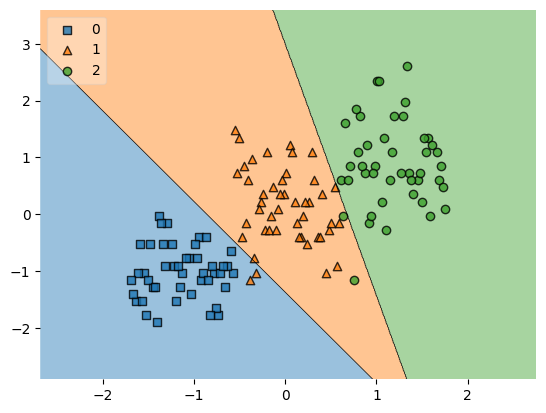

In [74]:
#to get the decision boundary of the model:

from sklearn.preprocessing import LabelEncoder
from sklearn.linear_model import LogisticRegression
from mlxtend.plotting import plot_decision_regions

le = LabelEncoder()
y_train_encoded = le.fit_transform(Y_train)

# Select the first two features
X_train_2d = X_train[:, :2]

clf_2d = LogisticRegression()
clf_2d.fit(X_train_2d, y_train_encoded)

plot_decision_regions(
    X_train_2d,
    y_train_encoded,
    clf=clf_2d,
    legend=2
)

In [75]:
#to find out which species is 0/1/2:
print(le.classes_)

['Iris-setosa' 'Iris-versicolor' 'Iris-virginica']


here, 0 -> Iris-setosa; 1 -> Iris-versicolor; 2-> Iris-virginica